**Prévision avec données météo:**
Remplacement des mesures du site par la météo Open-Meteo (réanalyse ERA5), puis prévision à différents horizons.

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

def cible_future(serie, minutes):
    # Valeur exactement à t + minutes (NaN si nuit ou trou entre les deux)
    return serie.reindex(serie.index + pd.Timedelta(minutes=minutes)).values

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 22.0,
    "longitude": 78.0,
    "start_date": "2020-05-15",
    "end_date": "2020-06-18",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "cloud_cover",
        "cloud_cover_low",
        "cloud_cover_mid",
        "cloud_cover_high",
        "shortwave_radiation",
        "direct_radiation",
        "diffuse_radiation",
        "wind_speed_10m",
        "precipitation"
    ],
    "timezone": "Asia/Kolkata"
}

reponse = requests.get(url, params=params)
donnees = reponse.json()
print(reponse.status_code)

200


In [3]:
meteo = pd.DataFrame(donnees["hourly"])
meteo["time"] = pd.to_datetime(meteo["time"])
meteo = meteo.set_index("time")

print(meteo.shape)
meteo.head()

(840, 11)


,temperature_2m,relative_humidity_2m,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,shortwave_radiation,direct_radiation,diffuse_radiation,wind_speed_10m,precipitation
time,,,,,,,,,,,
2020-05-15 00:00:00,30.3,44,32,0,32,1,0.0,0.0,0.0,14.1,0.0
2020-05-15 01:00:00,29.9,46,30,0,30,0,0.0,0.0,0.0,13.0,0.0
2020-05-15 02:00:00,29.5,46,29,0,29,0,0.0,0.0,0.0,12.2,0.0
2020-05-15 03:00:00,29.1,47,29,0,29,0,0.0,0.0,0.0,13.2,0.0
2020-05-15 04:00:00,28.4,49,52,0,48,21,0.0,0.0,0.0,14.1,0.0


In [4]:
# Ré-échantillonnage horaire → 15 min par interpolation
meteo_15 = meteo.resample("15min").interpolate(method="linear")
print(meteo_15.shape)

(3357, 11)


In [5]:
prod = pd.read_csv("data/dataset_jour.csv", index_col="DATE_TIME", parse_dates=True)

# On garde la production et on ajoute les variables météo prévues
data = prod[["AC_POWER_TOTAL"]].join(meteo_15, how="inner")

print(data.shape)
print(data.isna().sum().sum(), "valeurs manquantes")
data.head()

(1650, 12)
0 valeurs manquantes


,AC_POWER_TOTAL,temperature_2m,relative_humidity_2m,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,shortwave_radiation,direct_radiation,diffuse_radiation,wind_speed_10m,precipitation
DATE_TIME,,,,,,,,,,,,
2020-05-15 06:15:00,593.338690,28.825,61.0,23.5,0.0,20.50,5.5,56.25,21.75,34.50,5.825,0.0
2020-05-15 06:30:00,1480.194643,29.250,60.0,21.0,0.0,16.00,8.0,89.50,38.50,51.00,5.550,0.0
2020-05-15 06:45:00,2790.448214,29.675,59.0,18.5,0.0,11.50,10.5,122.75,55.25,67.50,5.275,0.0
2020-05-15 07:00:00,4052.662143,30.100,58.0,16.0,0.0,7.00,13.0,156.00,72.00,84.00,5.000,0.0
2020-05-15 07:15:00,4368.722619,30.650,55.5,12.5,0.0,5.75,10.0,211.75,114.00,97.75,6.500,0.0


In [6]:
corr = data.corr()["AC_POWER_TOTAL"].drop("AC_POWER_TOTAL").sort_values(ascending=False)
print(corr)

shortwave_radiation     0.706743
diffuse_radiation       0.676955
direct_radiation        0.617694
temperature_2m          0.317225
wind_speed_10m          0.235247
cloud_cover_low         0.075213
precipitation           0.026694
cloud_cover_high       -0.022082
cloud_cover            -0.038969
cloud_cover_mid        -0.061070
relative_humidity_2m   -0.193227
Name: AC_POWER_TOTAL, dtype: float64


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Variables temporelles (connues à l'avance, donc légitimes)
data["heure"] = data.index.hour + data.index.minute / 60
data["heure_sin"] = np.sin(2 * np.pi * data["heure"] / 24)
data["heure_cos"] = np.cos(2 * np.pi * data["heure"] / 24)

cible = "AC_POWER_TOTAL"
features = [c for c in data.columns if c != cible]

split = int(len(data) * 0.8)
Xtr, ytr = data[features].iloc[:split], data[cible].iloc[:split]
Xte, yte = data[features].iloc[split:], data[cible].iloc[split:]

rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(Xtr, ytr)
pred = rf.predict(Xte)

rmse = np.sqrt(mean_squared_error(yte, pred))
mae = mean_absolute_error(yte, pred)
print(f"RMSE : {rmse:.0f} kW | MAE : {mae:.0f} kW")
print(f"Skill score vs persistance (3075 kW) : {100*(1-rmse/3075):.1f} %")

RMSE : 4074 kW | MAE : 3069 kW
Skill score vs persistance (3075 kW) : -32.5 %


- Corrélation rayonnement / production : 0,71 (contre 0,99 pour le capteur du site), car la réanalyse est une moyenne sur une maille de plusieurs dizaines de km
- Météo seule : RMSE 4074 kW, moins bon que la persistance (3075 kW)
- → ajout de l'état récent de la centrale (retards de production)

In [8]:
# Ajouter l'état récent mesuré (disponible en opérationnel)
data["prod_lag_1"] = data[cible].shift(1)
data["prod_lag_2"] = data[cible].shift(2)
data["prod_lag_4"] = data[cible].shift(4)
data["prod_moy_1h"] = data[cible].rolling(4).mean().shift(1)

d2 = data.dropna()
features2 = [c for c in d2.columns if c != cible]

split2 = int(len(d2) * 0.8)
Xtr2, ytr2 = d2[features2].iloc[:split2], d2[cible].iloc[:split2]
Xte2, yte2 = d2[features2].iloc[split2:], d2[cible].iloc[split2:]

rf2 = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf2.fit(Xtr2, ytr2)
pred2 = rf2.predict(Xte2)

rmse2 = np.sqrt(mean_squared_error(yte2, pred2))
print(f"RMSE : {rmse2:.0f} kW | Skill score : {100*(1-rmse2/3075):.1f} %")

RMSE : 2891 kW | Skill score : 6.0 %


In [9]:
# Prévision à 1 h : cible = production exactement 1 h plus tard
d3 = data.copy()
d3["cible_1h"] = cible_future(d3[cible], 60)
d3 = d3.dropna()

features3 = [c for c in d3.columns if c != "cible_1h"]

split3 = int(len(d3) * 0.8)
Xtr3, ytr3 = d3[features3].iloc[:split3], d3["cible_1h"].iloc[:split3]
Xte3, yte3 = d3[features3].iloc[split3:], d3["cible_1h"].iloc[split3:]

# Persistance à 1 h : la production actuelle
pers_1h = d3[cible].iloc[split3:]
rmse_pers = np.sqrt(mean_squared_error(yte3, pers_1h))

rf3 = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf3.fit(Xtr3, ytr3)
pred3 = rf3.predict(Xte3)
rmse3 = np.sqrt(mean_squared_error(yte3, pred3))

print(f"Persistance 1h : {rmse_pers:.0f} kW")
print(f"Modèle 1h      : {rmse3:.0f} kW")
print(f"Skill score    : {100*(1-rmse3/rmse_pers):.1f} %")

Persistance 1h : 5581 kW
Modèle 1h      : 3898 kW
Skill score    : 30.2 %


Prévision à 1 h : RMSE 3898 kW contre 5581 kW pour la persistance → skill score 30 %.

In [10]:
horizons = [1, 2, 4, 8, 12, 24]  # 15 min à 6 h
resultats = []

for h in horizons:
    dh = data.copy()
    dh["cible"] = cible_future(dh[cible], h * 15)
    dh = dh.dropna()

    feats = [c for c in dh.columns if c != "cible"]
    s = int(len(dh) * 0.8)

    Xtr, ytr = dh[feats].iloc[:s], dh["cible"].iloc[:s]
    Xte, yte = dh[feats].iloc[s:], dh["cible"].iloc[s:]

    pers = dh[cible].iloc[s:]
    rmse_p = np.sqrt(mean_squared_error(yte, pers))

    m = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    m.fit(Xtr, ytr)
    rmse_m = np.sqrt(mean_squared_error(yte, m.predict(Xte)))

    resultats.append({
        "horizon_min": h * 15,
        "rmse_persistance": rmse_p,
        "rmse_modele": rmse_m,
        "skill": 100 * (1 - rmse_m / rmse_p)
    })

res = pd.DataFrame(resultats)
print(res.round(1))

   horizon_min  rmse_persistance  rmse_modele  skill
0           15            3058.5       2925.4    4.4
1           30            4213.5       3549.4   15.8
2           60            5580.8       3902.0   30.1
3          120            8605.4       4263.6   50.5
4          180           10913.3       4510.0   58.7
5          360           13164.0       4085.8   69.0


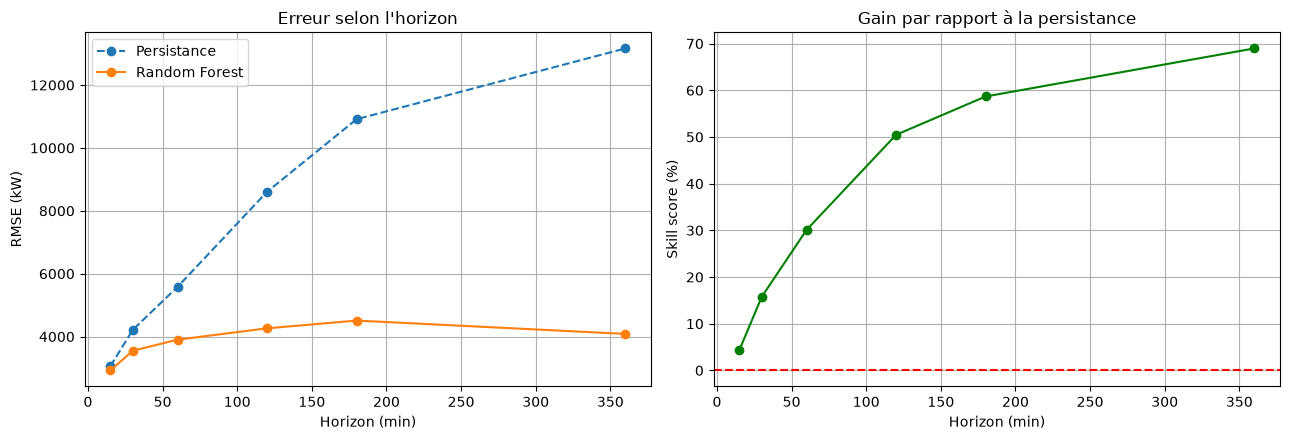

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(res["horizon_min"], res["rmse_persistance"], "o--", label="Persistance")
ax[0].plot(res["horizon_min"], res["rmse_modele"], "o-", label="Random Forest")
ax[0].set_xlabel("Horizon (min)")
ax[0].set_ylabel("RMSE (kW)")
ax[0].set_title("Erreur selon l'horizon")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(res["horizon_min"], res["skill"], "o-", color="green")
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Horizon (min)")
ax[1].set_ylabel("Skill score (%)")
ax[1].set_title("Gain par rapport à la persistance")
ax[1].grid(True)

plt.tight_layout()
plt.show()

L'erreur du modèle reste stable (3500 à 4500 kW) alors que celle de la persistance augmente avec l'horizon → gain faible à 15 min (4 %), 69 % à 6 h.

In [12]:
from xgboost import XGBRegressor

d = data.copy()
d["cible"] = cible_future(d[cible], 60)
d = d.dropna()

feats = [c for c in d.columns if c != "cible"]
s = int(len(d) * 0.8)

Xtr, ytr = d[feats].iloc[:s], d["cible"].iloc[:s]
Xte, yte = d[feats].iloc[s:], d["cible"].iloc[s:]

rmse_pers = np.sqrt(mean_squared_error(yte, d[cible].iloc[s:]))

modeles = {
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8, random_state=42)
}

for nom, m in modeles.items():
    m.fit(Xtr, ytr)
    r = np.sqrt(mean_squared_error(yte, m.predict(Xte)))
    print(f"{nom:15} RMSE : {r:.0f} kW | Skill : {100*(1-r/rmse_pers):.1f} %")

Random Forest   RMSE : 3898 kW | Skill : 30.2 %
XGBoost         RMSE : 4003 kW | Skill : 28.3 %


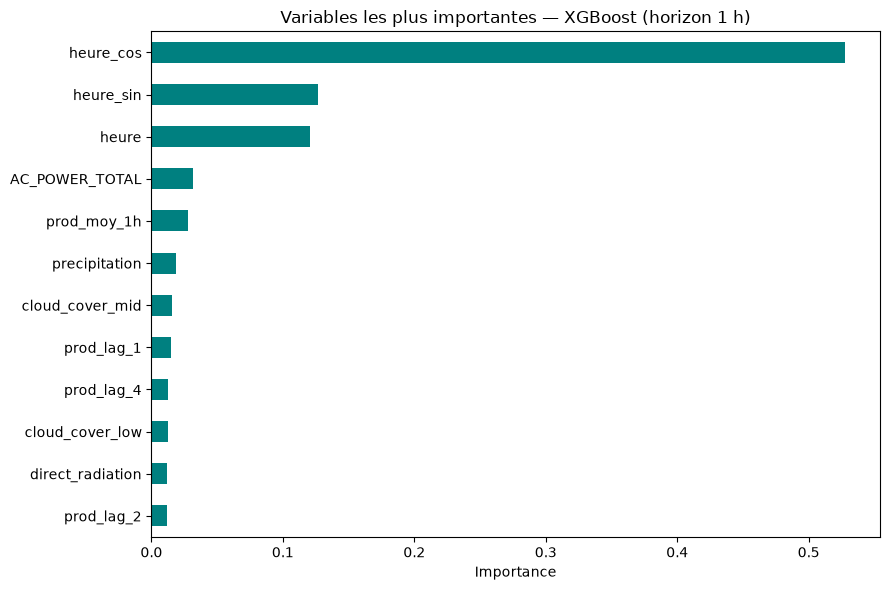

In [13]:
xgb = modeles["XGBoost"]
imp = pd.Series(xgb.feature_importances_, index=feats).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
imp.head(12).sort_values().plot(kind="barh", color="teal")
plt.title("Variables les plus importantes — XGBoost (horizon 1 h)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Random Forest > XGBoost (30 % contre 28 %) sur environ 1250 points d'entraînement. L'encodage horaire pèse plus de 80 % : le modèle apprend surtout le profil journalier moyen.

In [14]:
import joblib

# Réentraîner le meilleur modèle (Random Forest, horizon 1 h)
rf_final = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_final.fit(Xtr, ytr)

joblib.dump(rf_final, "modele_rf.pkl")
joblib.dump(feats, "features.pkl")

# Sauvegarder les prédictions sur le test pour le dashboard
sortie = pd.DataFrame({
    "reel": yte,
    "predit": rf_final.predict(Xte),
    "persistance": d[cible].iloc[s:]
}, index=yte.index)

sortie.to_csv("data/predictions.csv")
print(sortie.head())

                             reel        predit   persistance
DATE_TIME                                                    
2020-06-11 09:45:00  12771.435714  13873.487769  10287.671429
2020-06-11 10:00:00  15504.928571  15547.361953  11091.971429
2020-06-11 10:15:00  16784.860714  17548.186742  12068.066071
2020-06-11 10:30:00  15787.112500  19094.660899  12320.907143
2020-06-11 10:45:00  17764.082143  21173.257439  12771.435714


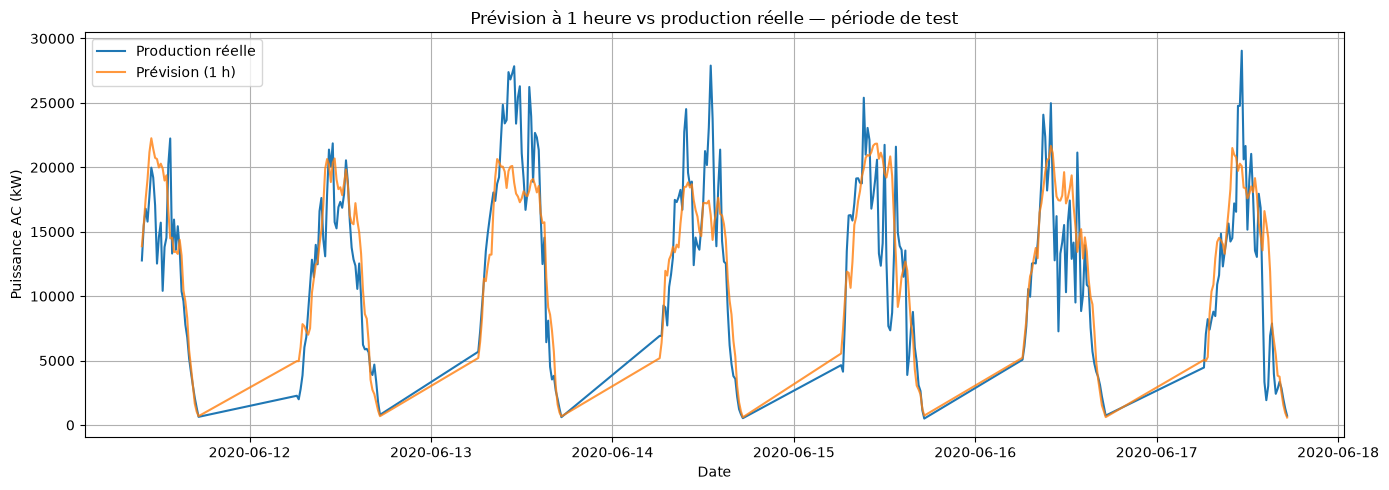

In [15]:
plt.figure(figsize=(14, 5))
plt.plot(sortie.index, sortie["reel"], label="Production réelle", linewidth=1.5)
plt.plot(sortie.index, sortie["predit"], label="Prévision (1 h)", linewidth=1.5, alpha=0.8)
plt.xlabel("Date")
plt.ylabel("Puissance AC (kW)")
plt.title("Prévision à 1 heure vs production réelle — période de test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

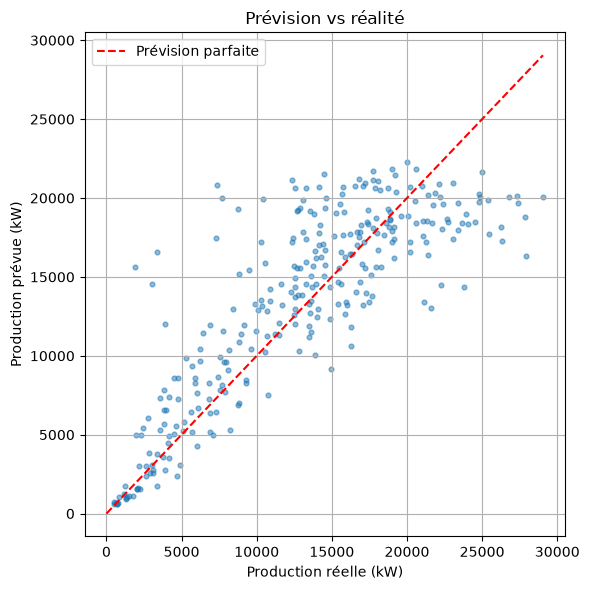

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(sortie["reel"], sortie["predit"], s=12, alpha=0.5)
lim = [0, max(sortie["reel"].max(), sortie["predit"].max())]
plt.plot(lim, lim, "r--", label="Prévision parfaite")
plt.xlabel("Production réelle (kW)")
plt.ylabel("Production prévue (kW)")
plt.title("Prévision vs réalité")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Prévision trop lisse : les passages nuageux ne sont pas anticipés, les pics sont sous-estimés et les creux surestimés.

**Conclusion:** Avec la météo : 3898 kW. Sans la météo (notebook 05) : 3930 kW. L'apport est négligeable, car la maille ERA5 est trop grossière pour capter les nuages au-dessus de la centrale. La prévision repose sur le profil horaire et l'état récent.